# 08 · 단백질 구조 예측 — AlphaFold · ESMFold · ESM-2
### 실습으로 배우는 신약개발 AI — 강의 목차 ⑩ 단백질 구조 예측

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/DrugAI/blob/main/08_Protein_Structure_Prediction.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① AlphaFold DB 에서 예측 구조 가져오기 ② 신뢰도 지표 **pLDDT·PAE** 해석 ③ 예측 구조 vs 실험 구조 비교(RMSD) ④ **ESMFold** 로 서열→구조 예측 ⑤ 단백질 언어모델 **ESM-2** 로 변이 영향 스캐닝 + AlphaMissense 와 비교 |
| **대상 단백질** | BACE-1(알츠하이머 표적) · 유비퀴틴(76 aa) · **KRAS**(항암 표적, G12C 저해제 소토라십) |
| **실행 환경** | CPU 가능 · 약 10분 (ESM-2 는 GPU 시 더 빠름) |

> 2024년 노벨화학상: **AlphaFold**(Hassabis·Jumper)와 단백질 설계(Baker). 이제 거의 모든 단백질의 구조 예측값을 무료로 받을 수 있습니다.

In [1]:
%pip install -q py3Dmol koreanize-matplotlib transformers
import koreanize_matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests, json, base64
import warnings; warnings.filterwarnings("ignore")
import py3Dmol
from IPython.display import HTML, display

HEADERS = {"User-Agent": "Mozilla/5.0 (Colab practice notebook)"}       # AlphaFold DB 파일 요청 시 필요
def get(url, **kw):
    r = requests.get(url, headers=HEADERS, timeout=120, **kw); r.raise_for_status(); return r

def show3d(view, width=740, height=480):
    b64 = base64.b64encode(view._make_html().encode()).decode()
    display(HTML(f'<iframe src="data:text/html;base64,{b64}" width="{width}" height="{height}" style="border:1px solid #ddd"></iframe>'))

def ca_table(pdb_text, chain=None):
    # PDB 텍스트에서 CA 원자의 (잔기번호, 좌표, B-factor) 추출
    rows = []
    for l in pdb_text.splitlines():
        if l.startswith("ATOM") and l[12:16].strip() == "CA" and (chain is None or l[21] == chain):
            rows.append((int(l[22:26]), float(l[30:38]), float(l[38:46]), float(l[46:54]), float(l[60:66])))
    return pd.DataFrame(rows, columns=["resi", "x", "y", "z", "b"]).drop_duplicates("resi").set_index("resi")
print("✅ 준비 완료")

Note: you may need to restart the kernel to use updated packages.


✅ 준비 완료


## 단백질 구조 기초
| 단계 | 의미 |
|---|---|
| 1차 구조 | 아미노산 서열 (20종 알파벳 문자열) |
| 2차 구조 | α-나선, β-시트 (국소 접힘) |
| 3차 구조 | 하나의 사슬이 접힌 3D 모양 → **약물이 붙는 pocket 형성** |
| 4차 구조 | 여러 사슬의 복합체 |

**구조를 얻는 방법**: 실험(X-선 결정학, Cryo-EM, NMR — 수개월~수년) vs **AI 예측(AlphaFold2·ESMFold — 수분)**

## 1. AlphaFold DB — BACE-1 예측 구조 가져오기
EMBL-EBI 의 **AlphaFold Protein Structure Database** 는 2억 개 이상 단백질의 예측 구조를 제공합니다. UniProt ID 만 있으면 API 로 즉시 다운로드합니다.

In [2]:
UNIPROT = "P56817"                                                           # BACE1_HUMAN
meta = get(f"https://alphafold.ebi.ac.uk/api/prediction/{UNIPROT}").json()[0]
print(meta["uniprotDescription"], "| 길이", len(meta["uniprotSequence"]), "aa | 평균 pLDDT", meta["globalMetricValue"])
af_pdb = get(meta["pdbUrl"]).text
af = ca_table(af_pdb)
print("예측 구조 잔기 수:", len(af))

Beta-secretase 1 | 길이 501 aa | 평균 pLDDT 87.5


예측 구조 잔기 수: 501


## 2. ⭐ 신뢰도 지표 ① pLDDT — 잔기별 국소 구조 신뢰도 (0~100)
AlphaFold 는 PDB 파일의 B-factor 자리에 **pLDDT** 를 저장합니다.

| pLDDT | 해석 |
|---|---|
| > 90 | 매우 높음 — 측쇄 원자 수준까지 신뢰 (도킹 가능) |
| 70~90 | 높음 — 주사슬(backbone) 신뢰 |
| 50~70 | 낮음 — 주의 |
| < 50 | 매우 낮음 — 무질서(disordered) 영역일 가능성 |

BACE-1 의 UniProt 주석(신호펩타이드·프로펩타이드·막관통 부위)과 함께 보면 **pLDDT 가 낮은 이유**를 이해할 수 있습니다.

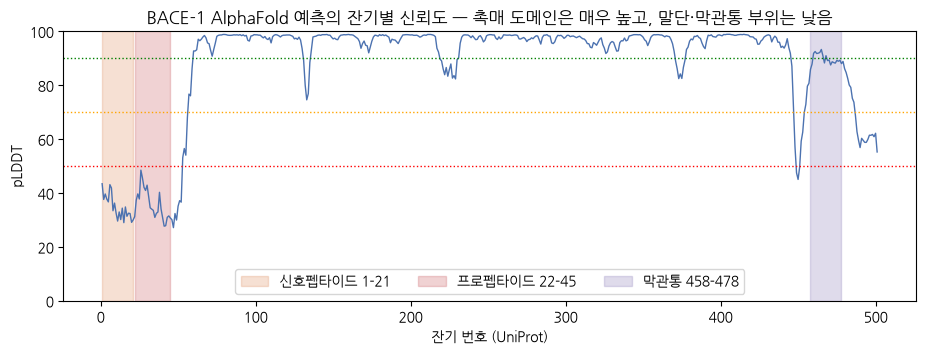

In [3]:
regions = {"신호펩타이드 1-21": (1, 21), "프로펩타이드 22-45": (22, 45), "막관통 458-478": (458, 478)}
plt.figure(figsize=(11, 3.5))
plt.plot(af.index, af["b"], color="#4C72B0", lw=1)
for (name, (s, e)), c in zip(regions.items(), ["#DD8452", "#C44E52", "#8172B3"]):
    plt.axvspan(s, e, color=c, alpha=0.25, label=name)
for th, c in [(90, "green"), (70, "orange"), (50, "red")]:
    plt.axhline(th, color=c, ls=":", lw=1)
plt.xlabel("잔기 번호 (UniProt)"); plt.ylabel("pLDDT"); plt.ylim(0, 100); plt.legend(loc="lower center", ncol=3)
plt.title("BACE-1 AlphaFold 예측의 잔기별 신뢰도 — 촉매 도메인은 매우 높고, 말단·막관통 부위는 낮음"); plt.show()

In [4]:
# pLDDT 색으로 3D 구조 보기 (AlphaFold 공식 색: 파랑>90, 하늘 70-90, 노랑 50-70, 주황<50)
view = py3Dmol.view(width=720, height=460)
view.addModel(af_pdb, "pdb")
view.setStyle({"cartoon": {"colorscheme": {"prop": "b", "gradient": "roygb", "min": 50, "max": 90}}})
view.zoomTo(); show3d(view)

## 3. 신뢰도 지표 ② PAE — "두 부위의 상대 위치를 얼마나 믿을 수 있나"
**PAE(Predicted Aligned Error, Å)**: 잔기 i 를 기준으로 맞췄을 때 잔기 j 위치의 예상 오차.
- 대각선 근처 블록이 진하면(오차 작음) 하나의 단단한 **도메인**
- 블록 사이가 밝으면(오차 큼) **도메인 간 배치가 불확실** → 다중 도메인·복합체 해석 시 pLDDT 보다 중요

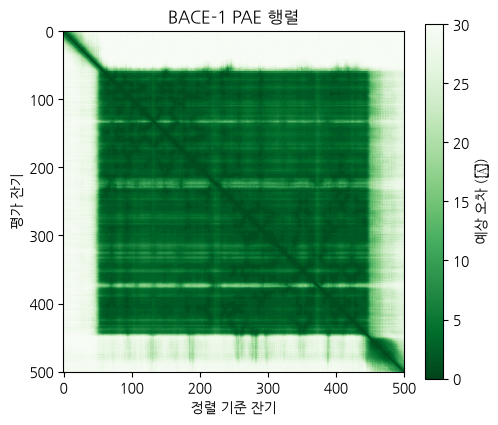

In [5]:
pae = np.array(get(meta["paeDocUrl"]).json()[0]["predicted_aligned_error"])
plt.figure(figsize=(5.5, 4.6))
plt.imshow(pae, cmap="Greens_r", vmin=0, vmax=30); plt.colorbar(label="예상 오차 (Å)")
plt.xlabel("정렬 기준 잔기"); plt.ylabel("평가 잔기"); plt.title("BACE-1 PAE 행렬"); plt.show()

## 4. 예측 구조 vs 실험 구조 — 얼마나 정확한가?
실험 구조 **PDB 4B05**(X-선, 1.8 Å)와 비교합니다. 4B05 의 잔기 번호는 성숙 효소 기준이라 **UniProt 번호 = PDB 번호 + 61** 입니다.
두 구조의 CA 원자를 **Kabsch 알고리즘**으로 최적 겹침(superposition) 후 RMSD 를 계산합니다.

공통 잔기 366개, CA RMSD = 0.90 Å  (2 Å 이하면 실험 구조와 거의 동일)


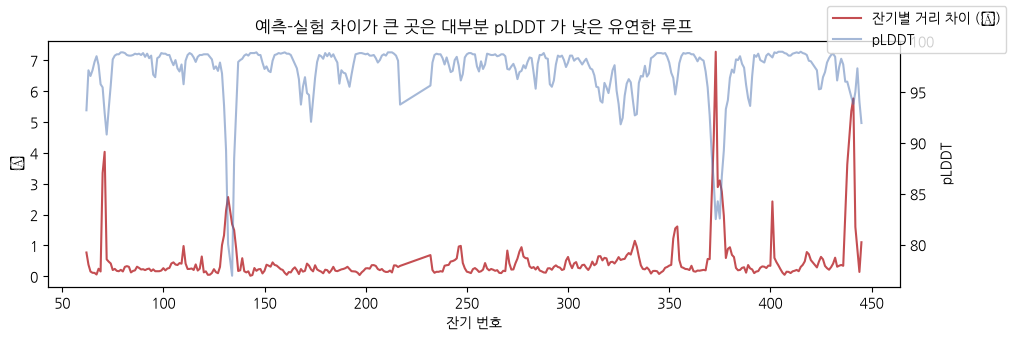

In [6]:
xr_pdb = get("https://files.rcsb.org/download/4B05.pdb").text
xr = ca_table(xr_pdb, chain="A")
xr = xr[(xr.index >= 1) & (xr.index <= 392)]
xr.index = xr.index + 61                                               # PDB → UniProt 번호
common = af.index.intersection(xr.index)
P, Q = af.loc[common, ["x", "y", "z"]].values, xr.loc[common, ["x", "y", "z"]].values

def kabsch_rmsd(P, Q):
    Pc, Qc = P - P.mean(0), Q - Q.mean(0)
    U, S, Vt = np.linalg.svd(Pc.T @ Qc)
    d = np.sign(np.linalg.det(Vt.T @ U.T))
    R = Vt.T @ np.diag([1, 1, d]) @ U.T
    P_rot = Pc @ R.T
    return np.sqrt(((P_rot - Qc) ** 2).sum(1).mean()), np.sqrt(((P_rot - Qc) ** 2).sum(1))

rmsd, per_res = kabsch_rmsd(P, Q)
print(f"공통 잔기 {len(common)}개, CA RMSD = {rmsd:.2f} Å  (2 Å 이하면 실험 구조와 거의 동일)")
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(common, per_res, color="#C44E52", label="잔기별 거리 차이 (Å)"); ax.set_ylabel("Å"); ax.set_xlabel("잔기 번호")
ax2 = ax.twinx(); ax2.plot(common, af.loc[common, "b"], color="#4C72B0", alpha=0.5, label="pLDDT"); ax2.set_ylabel("pLDDT")
ax.set_title("예측-실험 차이가 큰 곳은 대부분 pLDDT 가 낮은 유연한 루프"); fig.legend(loc="upper right"); plt.show()

In [7]:
# 결합 pocket 잔기(AZD3839 로부터 5 Å 이내)의 pLDDT — 도킹에 예측 구조를 써도 되는지 판단
lig = np.array([[float(l[30:38]), float(l[38:46]), float(l[46:54])] for l in xr_pdb.splitlines()
                if l.startswith("HETATM") and l[17:20] == "32D"])
pocket = set()
for l in xr_pdb.splitlines():
    if l.startswith("ATOM") and l[21] == "A":
        xyz = np.array([float(l[30:38]), float(l[38:46]), float(l[46:54])])
        if np.min(np.linalg.norm(lig - xyz, axis=1)) < 5 and 1 <= int(l[22:26]) <= 392:
            pocket.add(int(l[22:26]) + 61)
pocket = sorted(pocket)
print(f"pocket 잔기 {len(pocket)}개, 평균 pLDDT = {af.loc[pocket, 'b'].mean():.1f}, 최소 = {af.loc[pocket, 'b'].min():.1f}")
print("→ pocket 의 pLDDT 가 90 이상이면 예측 구조로도 도킹을 시도할 수 있습니다 (단, 리간드 유도 변화(induced fit)는 반영 안 됨).")

pocket 잔기 24개, 평균 pLDDT = 95.1, 최소 = 76.9
→ pocket 의 pLDDT 가 90 이상이면 예측 구조로도 도킹을 시도할 수 있습니다 (단, 리간드 유도 변화(induced fit)는 반영 안 됨).


## 5. ESMFold — 서열만 넣으면 수 초 만에 구조 예측
**ESMFold**(Meta)는 단백질 언어모델 ESM-2 위에 구조 모듈을 얹은 모델로, AlphaFold 와 달리 **다중서열정렬(MSA) 검색이 필요 없어 매우 빠릅니다.**
유비퀴틴(76 aa) 서열로 구조를 예측하고 실험 구조(PDB 1UBQ)와 비교합니다.

In [8]:
ubq_seq = "MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG"
esm_pdb = None
try:
    r = requests.post("https://api.esmatlas.com/foldSequence/v1/pdb/", data=ubq_seq, timeout=120, verify=False)
    if r.status_code == 200 and "ATOM" in r.text:
        esm_pdb = r.text
except Exception as e:
    print("ESMFold API 호출 실패:", e)
if esm_pdb is None:
    print("⚠️ ESMFold 공개 API 가 응답하지 않습니다(혼잡/점검). 대안: ColabFold 노트북 또는 HuggingFace 'facebook/esmfold_v1'(GPU)")
else:
    esm = ca_table(esm_pdb)
    # ESMFold API 는 pLDDT 를 0~1 로 저장하는 경우가 있어 0~100 으로 맞춤
    if esm["b"].max() <= 1.0: esm["b"] *= 100
    ref = ca_table(get("https://files.rcsb.org/download/1UBQ.pdb").text, chain="A")
    c = esm.index.intersection(ref.index)
    r_, _ = kabsch_rmsd(esm.loc[c, ["x", "y", "z"]].values, ref.loc[c, ["x", "y", "z"]].values)
    print(f"ESMFold 평균 pLDDT {esm['b'].mean():.1f}, 실험 구조(1UBQ) 대비 CA RMSD = {r_:.2f} Å")
    view = py3Dmol.view(width=600, height=400); view.addModel(esm_pdb, "pdb")
    view.setStyle({"cartoon": {"color": "spectrum"}}); view.zoomTo(); show3d(view, 620, 420)

ESMFold 평균 pLDDT 90.5, 실험 구조(1UBQ) 대비 CA RMSD = 0.83 Å


| 방법 | 속도 | 정확도 | 적합 상황 |
|---|---|---|---|
| **AlphaFold DB** | 즉시 (사전 계산) | 높음 | 알려진 UniProt 단백질 |
| **ESMFold** | 수 초 | 좋음 | 빠른 확인, 설계 서열·변이체 |
| **ColabFold (AlphaFold2)** | 수십 분 (GPU) | 최고 수준 | 새 서열, 복합체(multimer) |
| **AlphaFold 3 / Boltz-2 / Chai-1** | 분~시간 | 복합체+리간드 | 단백질-리간드·핵산 복합체 |

## 6. ⭐ 단백질 언어모델 ESM-2 — 변이 영향 스캐닝 (KRAS)
**ESM-2** 는 수억 개 단백질 서열을 **빈칸 맞히기(masked language model)** 로 학습했습니다. 그 결과 "이 위치에 어떤 아미노산이 자연스러운가"를 압니다.

**변이 점수(wild-type marginal)** = log P(변이 아미노산) − log P(야생형 아미노산)
- 음수로 클수록 → 진화적으로 허용되지 않는 변이 → 기능 손상 가능성 ↑
- **보존 위치**(어떤 변이도 불리)는 기능·구조 핵심 부위

대상: **KRAS** (189 aa) — 암에서 가장 흔한 발암 유전자, G12C 변이를 표적으로 한 **소토라십**(2021 FDA 승인)

In [9]:
import torch
from transformers import AutoTokenizer, EsmForMaskedLM
import transformers; transformers.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()
device = "cuda" if torch.cuda.is_available() else "cpu"
esm_name = "facebook/esm2_t12_35M_UR50D"            # 3,500만 파라미터 경량 모델
tok = AutoTokenizer.from_pretrained(esm_name)
esm2 = EsmForMaskedLM.from_pretrained(esm_name).to(device).eval()

kras_meta = get("https://alphafold.ebi.ac.uk/api/prediction/P01116").json()[0]
kras = kras_meta["uniprotSequence"]
AA = list("ACDEFGHIKLMNPQRSTVWY")
with torch.no_grad():
    enc = tok(kras, return_tensors="pt").to(device)
    logp = torch.log_softmax(esm2(**enc).logits[0, 1:-1], dim=-1).cpu()     # 앞뒤 특수토큰 제외
aa_ids = [tok.convert_tokens_to_ids(a) for a in AA]
wt_ids = [tok.convert_tokens_to_ids(a) for a in kras]
score = (logp[:, aa_ids] - logp[torch.arange(len(kras)), wt_ids].unsqueeze(1)).numpy()   # (길이, 20)
print("KRAS 길이:", len(kras), " 변이 점수 행렬:", score.shape)

KRAS 길이: 189  변이 점수 행렬: (189, 20)


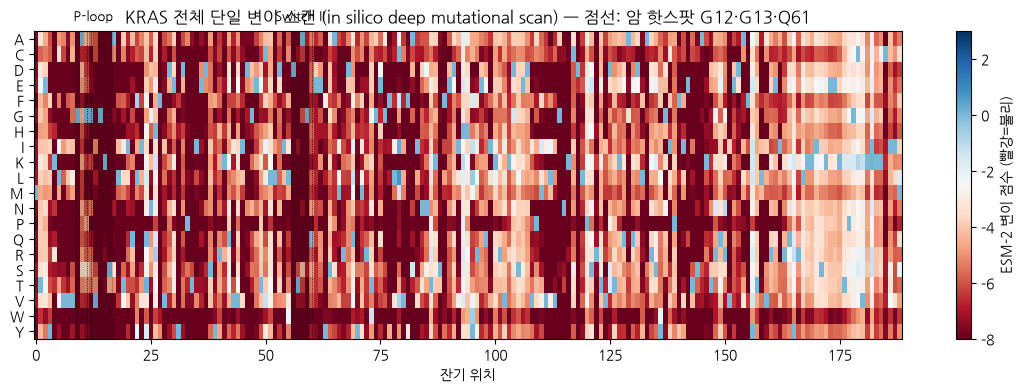

가장 보존된(변이에 민감한) 위치 10개: ['D57', 'G15', 'D119', 'G10', 'L53', 'G60', 'L19', 'I55', 'S17', 'K16']
  G12: 평균 점수 -6.20, 보존 순위 91/189
  G13: 평균 점수 -7.23, 보존 순위 61/189
  Q61: 평균 점수 -5.94, 보존 순위 101/189


In [10]:
plt.figure(figsize=(14, 4))
plt.imshow(score.T, aspect="auto", cmap="RdBu", vmin=-8, vmax=3)
plt.yticks(range(20), AA); plt.xlabel("잔기 위치"); plt.colorbar(label="ESM-2 변이 점수 (빨강=불리)")
for (s_, e_), name in [((10, 17), "P-loop"), ((57, 60), "Switch II")]:
    plt.axvspan(s_ - 1.5, e_ - 0.5, color="k", alpha=0.12); plt.text((s_ + e_) / 2 - 1, -1.2, name, ha="center", fontsize=9)
for p in (12, 13, 61):
    plt.axvline(p - 1, color="k", lw=0.6, ls=":")
plt.title("KRAS 전체 단일 변이 스캔 (in silico deep mutational scan) — 점선: 암 핫스팟 G12·G13·Q61"); plt.show()

cons = pd.Series(score.mean(1), index=[f"{a}{i+1}" for i, a in enumerate(kras)])
rank = cons.rank()                                   # 1 = 가장 보존(변이에 가장 민감)
print("가장 보존된(변이에 민감한) 위치 10개:", list(cons.sort_values().index[:10]))
for k in ["G12", "G13", "Q61"]:
    print(f"  {k}: 평균 점수 {cons[k]:.2f}, 보존 순위 {int(rank[k])}/{len(cons)}")

### 두 AI 모델 비교 — ESM-2 vs AlphaMissense
**AlphaMissense**(DeepMind, 2023)는 AlphaFold 구조 정보와 단백질 언어모델을 결합해 **모든 단일 아미노산 변이의 병원성**을 예측했습니다. AlphaFold DB 에서 바로 받을 수 있습니다.
비지도 언어모델(ESM-2)의 점수가 AlphaMissense 와 얼마나 일치하는지 확인합니다.

변이 3591개, 스피어만 상관 = -0.76  (음의 상관 = ESM-2 가 불리하다고 본 변이를 AlphaMissense 도 병원성으로 판단)


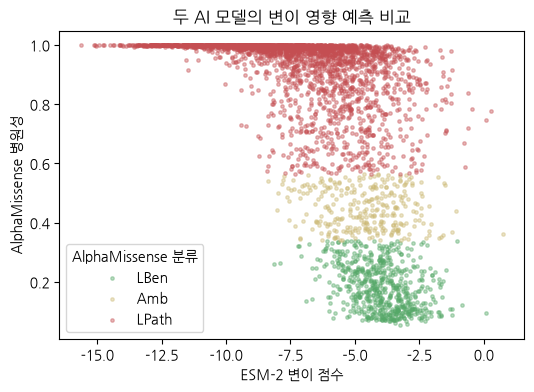

In [11]:
from io import StringIO
from scipy.stats import spearmanr
am = pd.read_csv(StringIO(get(kras_meta["amAnnotationsUrl"]).text))
am["pos"] = am["protein_variant"].str[1:-1].astype(int); am["mut"] = am["protein_variant"].str[-1]
am["esm2"] = [score[p - 1, AA.index(m)] for p, m in zip(am["pos"], am["mut"])]
rho = spearmanr(am["esm2"], am["am_pathogenicity"]).correlation
print(f"변이 {len(am)}개, 스피어만 상관 = {rho:.2f}  (음의 상관 = ESM-2 가 불리하다고 본 변이를 AlphaMissense 도 병원성으로 판단)")
plt.figure(figsize=(6, 4))
for cls, c in [("LBen", "#55A868"), ("Amb", "#CCB974"), ("LPath", "#C44E52")]:
    s = am[am["am_class"] == cls]; plt.scatter(s["esm2"], s["am_pathogenicity"], s=6, alpha=0.4, color=c, label=cls)
plt.xlabel("ESM-2 변이 점수"); plt.ylabel("AlphaMissense 병원성"); plt.legend(title="AlphaMissense 분류"); plt.title("두 AI 모델의 변이 영향 예측 비교"); plt.show()

> **해석**: 가장 보존된 위치는 GTP 결합 모티프인 **P-loop(G10–S17)** 과 **Switch II(D57–G60)** 입니다.
> 암 핫스팟 G12·G13·Q61 변이는 단백질을 '망가뜨리는' 변이가 아니라 GTP 가수분해를 막아 **신호를 계속 켜는 기능획득(gain-of-function)** 변이입니다.
> 언어모델 점수는 "진화적으로 허용되는가"를 말할 뿐, **기능 획득/상실의 방향**은 알려주지 않는다는 점에 주의하세요.

## 🧪 LLM 코딩 과제
```
AlphaFold DB API(https://alphafold.ebi.ac.uk/api/prediction/{UniProt ID})를 이용해서
EGFR(P00533)의 예측 구조를 받아 잔기별 pLDDT 그래프를 그리고, pLDDT 50 미만 구간을 표로 정리해줘.
requests 요청 시 headers={'User-Agent': 'Mozilla/5.0'} 를 넣어줘.
```

In [12]:
# ✏️ LLM 코드 붙여넣기

## ✅ 정리 & 현장 응용
- **AlphaFold DB**: UniProt ID 로 예측 구조 즉시 확보 — 실험 구조가 없을 때의 출발점
- **pLDDT**(국소 신뢰도) + **PAE**(도메인 간 배치 신뢰도)를 반드시 함께 확인. 특히 **pocket 잔기의 pLDDT**
- 예측 구조는 촉매 도메인 수준에서 실험 구조와 매우 가깝지만(RMSD ~1 Å), **리간드 결합에 의한 구조 변화**는 반영하지 못함
- **ESMFold**: MSA 없이 빠른 구조 예측 / **ESM-2**: 변이 영향·보존 위치 → 단백질 공학·항체 최적화·변이 해석
- 활용: 신규 표적 구조 확보 → pocket 탐색 → 도킹(예제 07) / 변이체 약물 내성 분석 / 생물의약품 안정성 설계

➡️ **다음 예제 09**: 어떤 단백질을 표적으로 삼을까? — **오믹스·네트워크 데이터로 신약 타겟 발굴**